In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from statsmodels.tsa.seasonal import seasonal_decompose, STL

In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/marcopeix/AppliedTimeSeriesAnalysisWithPython/main/data/jj.csv')
df.head()

In [ ]:
df.tail()

In [ ]:
decomposition = STL(df['data'], period=12).fit()
fig, (ax1, ax2, ax3, ax4) = plt.subplots(nrows=4, ncols=1, sharex=True,figsize=(10,8))
ax1.plot(decomposition.observed)
ax1.set_ylabel('Observed')
ax2.plot(decomposition.trend)
ax2.set_ylabel('Trend')
ax3.plot(decomposition.seasonal)
ax3.set_ylabel('Seasonal')
ax4.plot(decomposition.resid)
ax4.set_ylabel('Residuals')
plt.xticks(np.arange(0, 83, 4), np.arange(1960, 1981, 1))
fig.autofmt_xdate()
plt.tight_layout()

In [ ]:
from itertools import product

ps = range(0, 13, 1)
qs = range(0, 13, 1)
Ps = [0]
Qs = [0]

d = 2
D = 0
s = 12

ARIMA_order_list = list(product(ps, qs, Ps, Qs))

In [ ]:
from typing import Union
from tqdm import tqdm_notebook
from statsmodels.tsa.statespace.sarimax import SARIMAX
def optimize_SARIMA(endog: Union[pd.Series, list], order_list: list, d:int, D: int, s: int) -> pd.DataFrame:
    results = []
    for order in tqdm_notebook(order_list):
        model = SARIMAX(endog,order=(order[0], d, order[1]),
                        seasonal_order=(order[2], D, order[3], s),
                        simple_differencing=False).fit(disp=False)
        aic = model.aic
        results.append([order, aic])
    result_df = pd.DataFrame(results)
    result_df.columns = ['(p,q,P,Q)', 'AIC']
    result_df.sort_values(by='AIC', ascending=True).reset_index(drop=True)
    return result_df

In [ ]:
train = df[:-4]['data']

In [ ]:
ARIMA_result_df = optimize_SARIMA(train, ARIMA_order_list, d, D, s)

In [ ]:
ARIMA_result_df

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:997: UserWarning: Non-stationary starting seasonal autoregressive Using zeros as starting parameters.
  warn('Non-stationary starting seasonal autoregressive'
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


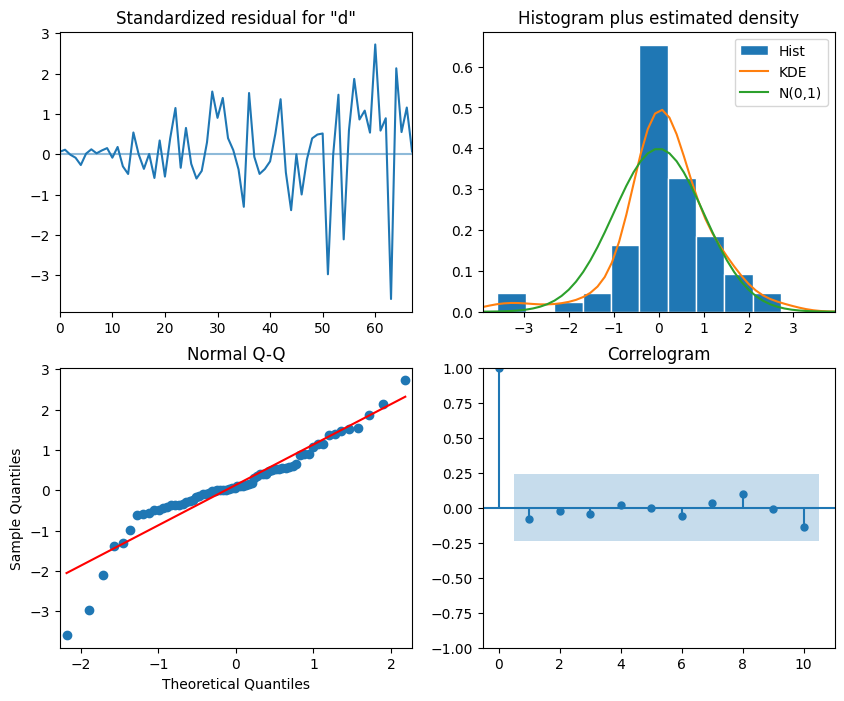

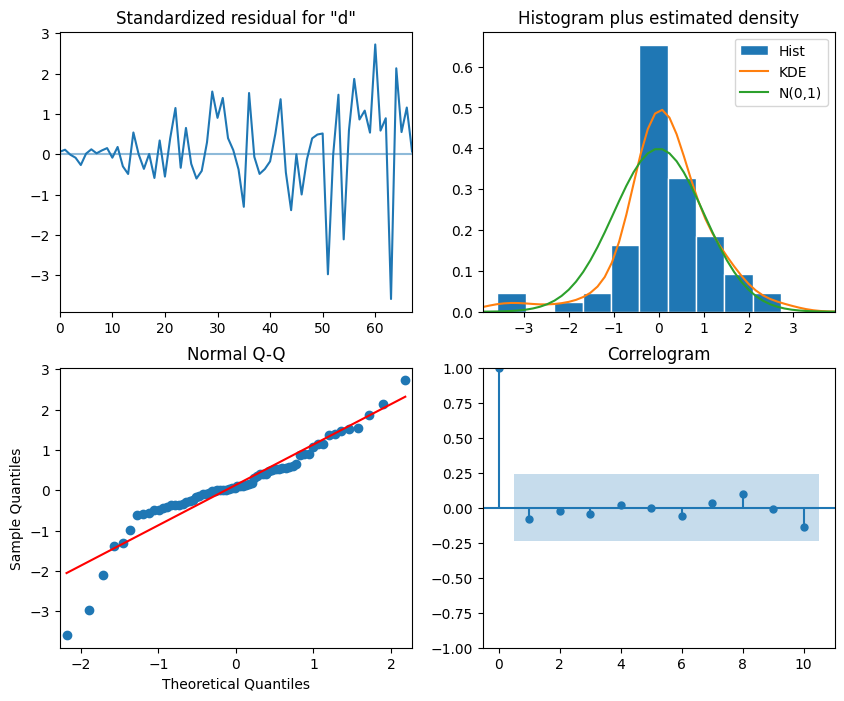

In [137]:
arima_model = SARIMAX(train, order=(3, 2, 7), seasonal_order=(3,1,2,10), simple_differencing=False)
model_fit = arima_model.fit(disp=False)
model_fit.plot_diagnostics(figsize=(10,8))

In [122]:
from statsmodels.stats.diagnostic import acorr_ljungbox
residuals = model_fit.resid
acorr_ljungbox(residuals, np.arange(1, 11, 1)) 


,lb_stat,lb_pvalue
1,1.786540,0.181348
2,2.412624,0.299299
3,4.505535,0.211797
4,5.709371,0.221929
5,5.923795,0.313705
6,5.925347,0.431605
7,6.024546,0.536886
8,7.739138,0.459358
9,7.739490,0.560598
10,9.174256,0.515650


/var/folders/hv/y00c8cl91z34xlwn9xbh5cfr0000gn/T/ipykernel_40028/427395805.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test['naive_seasonal'] = df['data'].iloc[76:80].values


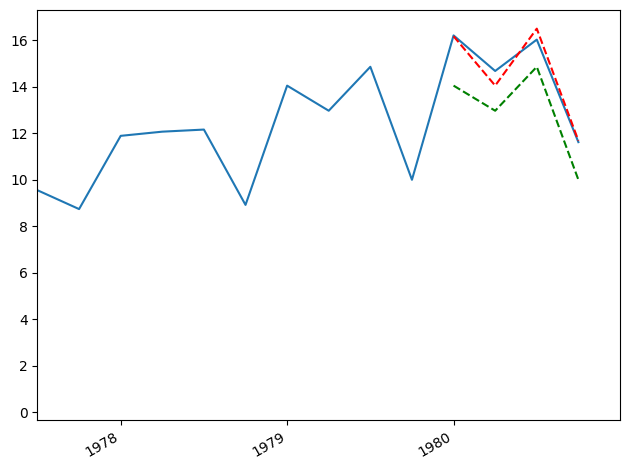

In [142]:
test = df[-4:]
predictions = model_fit.get_prediction(80, 83).predicted_mean
test['naive_seasonal'] = df['data'].iloc[76:80].values
fig, ax = plt.subplots()
ax.plot(df.date, df['data'])
ax.plot(predictions, 'r--')
ax.plot(test['naive_seasonal'], 'g--')
plt.xticks(np.arange(0, 83, 4), np.arange(1960, 1981, 1))
ax.set_xlim(70, 84)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [127]:
from statsmodels.tsa.stattools import adfuller
adf = adfuller(df['data'])
print(adf[:2])
adf = adfuller(np.diff(df['data']))
print(adf[:2])
adf = adfuller(np.diff(df['data'], 12))
print(adf[:2])

(2.742016573457475, 1.0)
(-0.40740976363803183, 0.9088542416911329)
(-11.256297183607913, 1.6638983407883838e-20)


In [139]:
np.mean(np.abs((predictions - test['data']) / test['data'])) * 100, np.mean(np.abs((test['naive_seasonal'] - test['data']) / test['data'])) * 100

(1.9933247676374843, 11.561658552433654)